In [1]:
import sys
print(sys.executable)
print(sys.version)

c:\python314\python.exe
3.14.6 (tags/v3.14.6:c63aec6, Jun 10 2026, 10:26:10) [MSC v.1944 64 bit (AMD64)]


In [2]:

import pandas as pd

df = pd.read_csv("Olympic_Games_Medal_Tally.csv")

df.head()


,edition,edition_id,year,country,country_noc,gold,silver,bronze,total
0,1896 Summer Olympics,1,1896,United States,USA,11,7,2,20
1,1896 Summer Olympics,1,1896,Greece,GRE,10,18,19,47
2,1896 Summer Olympics,1,1896,Germany,GER,6,5,2,13
3,1896 Summer Olympics,1,1896,France,FRA,5,4,2,11
4,1896 Summer Olympics,1,1896,Great Britain,GBR,2,3,2,7


In [3]:
print("Dataset size:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset information:")
df.info()

Dataset size: (1807, 9)

Column names:
['edition', 'edition_id', 'year', 'country', 'country_noc', 'gold', 'silver', 'bronze', 'total']

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 1807 entries, 0 to 1806
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype
---  ------       --------------  -----
 0   edition      1807 non-null   str  
 1   edition_id   1807 non-null   int64
 2   year         1807 non-null   int64
 3   country      1807 non-null   str  
 4   country_noc  1807 non-null   str  
 5   gold         1807 non-null   int64
 6   silver       1807 non-null   int64
 7   bronze       1807 non-null   int64
 8   total        1807 non-null   int64
dtypes: int64(6), str(3)
memory usage: 127.2 KB


In [4]:
# Check missing values in each column
print(df.isnull().sum())

# Check duplicate rows
print("Duplicate rows:", df.duplicated().sum())

edition        0
edition_id     0
year           0
country        0
country_noc    0
gold           0
silver         0
bronze         0
total          0
dtype: int64
Duplicate rows: 0


In [12]:
# Keep only Summer Olympic editions
summer_df = df[df["edition"].str.contains("Summer", case=False, na=False)].copy()

# Add up medals across all Summer Olympic editions for each country
top_5 = (
    summer_df.groupby("country")["total"]
    .sum()
    .sort_values(ascending=False)
    .head(5)
)

# Display the five countries with the highest historical medal totals
print(top_5)

country
United States    2655
Soviet Union     1010
Great Britain     927
Germany           791
France            773
Name: total, dtype: int64


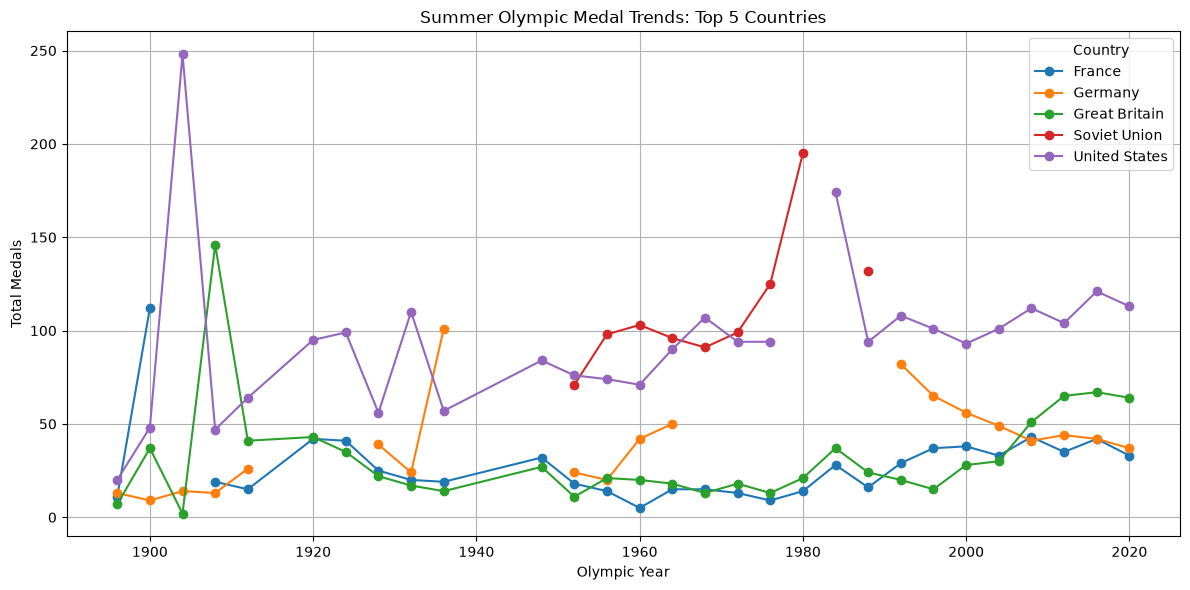

In [ ]:
# Keep records for the five selected countries
trend_df = summer_df[summer_df["country"].isin(top_5.index)]

# Combine medal totals by country and Olympic year
trend_df = trend_df.groupby(["year", "country"])["total"].sum().reset_index()

# Reshape data so each country becomes a separate line
trend_table = trend_df.pivot(index="year", columns="country", values="total")

# Draw the medal trend line chart
trend_table.plot(figsize=(12, 6), marker="o")

# Add chart labels and title
plt.title("Summer Olympic Medal Trends: Top 5 Countries")
plt.xlabel("Olympic Year")
plt.ylabel("Total Medals")
plt.grid(True)
plt.legend(title="Country")
plt.tight_layout()
plt.show()

## EDA Question 2: Participation Trends Across Gender, Age and Sports

In [5]:
import pandas as pd
# Load the athlete event results and athlete biography datasets
athlete_results = pd.read_csv("Olympic_Athlete_Event_Results.csv")
athlete_bio = pd.read_csv("Olympic_Athlete_Bio.csv")

# Display the actual column names before analysis
print("Athlete Event Results Columns:")
print(athlete_results.columns.tolist())

print("\nAthlete Bio Columns:")
print(athlete_bio.columns.tolist())


Athlete Event Results Columns:
['edition', 'edition_id', 'country_noc', 'sport', 'event', 'result_id', 'athlete', 'athlete_id', 'pos', 'medal', 'isTeamSport']

Athlete Bio Columns:
['athlete_id', 'name', 'sex', 'born', 'height', 'weight', 'country', 'country_noc', 'description', 'special_notes']


In [6]:

# Keep only the columns needed for gender participation analysis
gender_data = athlete_bio[['athlete_id', 'sex']].copy()

# Remove rows where gender information is missing
gender_data = gender_data.dropna(subset=['sex'])

# Count unique athletes for each gender
gender_counts = gender_data.groupby('sex')['athlete_id'].nunique()

# Display the total number of athletes by gender in the biography dataset
print("Athletes by Gender:")
print(gender_counts)


Athletes by Gender:
sex
Female     40334
Male      115527
Name: athlete_id, dtype: int64


In [7]:

# Display a few Olympic editions to understand their actual format
print(athlete_results['edition'].head(10).to_list())

# Check how many unique editions are present
print("\nTotal unique editions:", athlete_results['edition'].nunique())

# Check for missing athlete IDs in both datasets
print("\nMissing athlete IDs in results:", athlete_results['athlete_id'].isna().sum())
print("Missing athlete IDs in bio:", athlete_bio['athlete_id'].isna().sum())


['1908 Summer Olympics', '1908 Summer Olympics', '1908 Summer Olympics', '1908 Summer Olympics', '1908 Summer Olympics', '1908 Summer Olympics', '1908 Summer Olympics', '1908 Summer Olympics', '1908 Summer Olympics', '1908 Summer Olympics']

Total unique editions: 55

Missing athlete IDs in results: 0
Missing athlete IDs in bio: 0


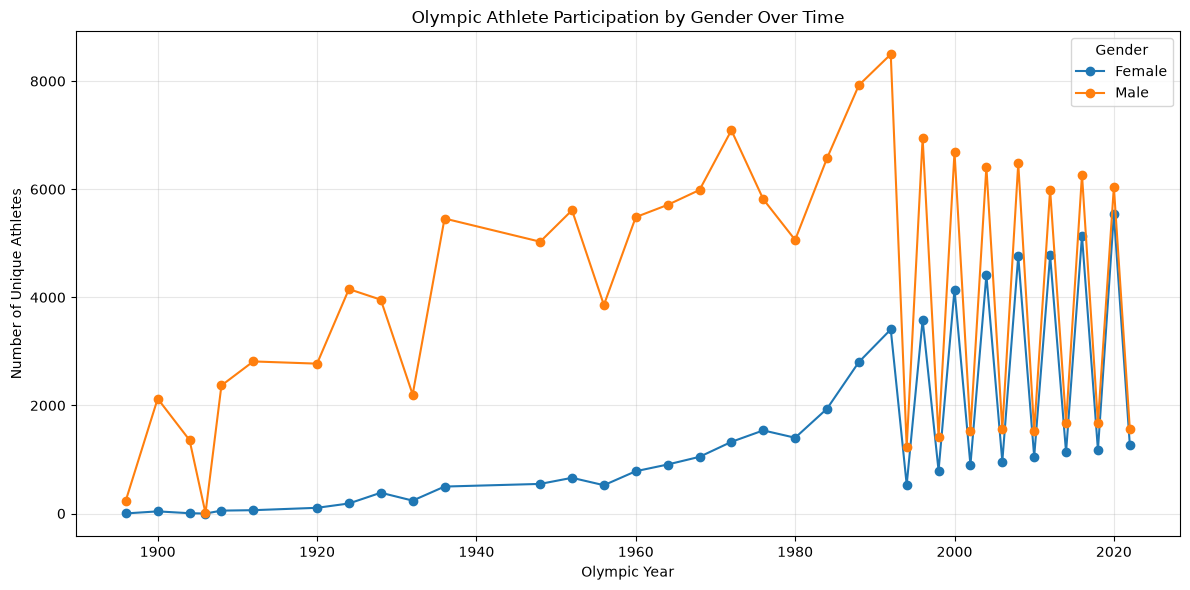

In [9]:
import matplotlib.pyplot as plt
# Extract the Olympic year from the edition name
athlete_results['year'] = athlete_results['edition'].str[:4].astype(int)

# Keep only the columns needed to analyse gender participation
gender_data = athlete_results[['athlete_id', 'year']].merge(
    athlete_bio[['athlete_id', 'sex']],
    on='athlete_id',
    how='left'
)

# Count unique athletes by year and gender
gender_trends = gender_data.groupby(
    ['year', 'sex']
)['athlete_id'].nunique().unstack(fill_value=0)

# Plot male and female participation over time
gender_trends.plot(figsize=(12, 6), marker='o')

# Add chart labels and formatting
plt.title('Olympic Athlete Participation by Gender Over Time')
plt.xlabel('Olympic Year')
plt.ylabel('Number of Unique Athletes')
plt.legend(title='Gender')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


In [10]:

# Inspect birth-date values before calculating athlete ages
print("Sample birth dates:")
print(athlete_bio['born'].head(10))

# Check how many birth dates are missing
print("\nMissing birth dates:", athlete_bio['born'].isna().sum())

# Check the data type of the birth-date column
print("\nBirth-date column type:", athlete_bio['born'].dtype)


Sample birth dates:
0        4 April 1949
1       15 March 1977
2    14 December 1986
3     12 January 1908
4       28 April 1900
5     9 November 1997
6    13 December 1996
7      4 October 1975
8     25 January 1982
9        6 March 1916
Name: born, dtype: str

Missing birth dates: 4053

Birth-date column type: str


In [11]:

# Convert birth-date strings into datetime values
athlete_bio['born'] = pd.to_datetime(
    athlete_bio['born'],
    format='%d %B %Y',
    errors='coerce'
)

# Extract the birth year from the converted dates
athlete_bio['birth_year'] = athlete_bio['born'].dt.year

# Extract the Olympic year from each edition
athlete_results['year'] = athlete_results['edition'].str[:4].astype(int)

# Join Olympic results with athlete birth years
age_data = athlete_results[['athlete_id', 'year', 'sport']].merge(
    athlete_bio[['athlete_id', 'birth_year']],
    on='athlete_id',
    how='left'
)

# Calculate approximate age during each Olympic edition
age_data['age'] = age_data['year'] - age_data['birth_year']

# Remove rows with missing or unrealistic ages
age_data = age_data[
    age_data['age'].between(10, 100)
].copy()

# Display basic age statistics
print(age_data['age'].describe().round(1))


count    306888.0
mean         26.0
std           6.3
min          11.0
25%          22.0
50%          25.0
75%          29.0
max          98.0
Name: age, dtype: float64


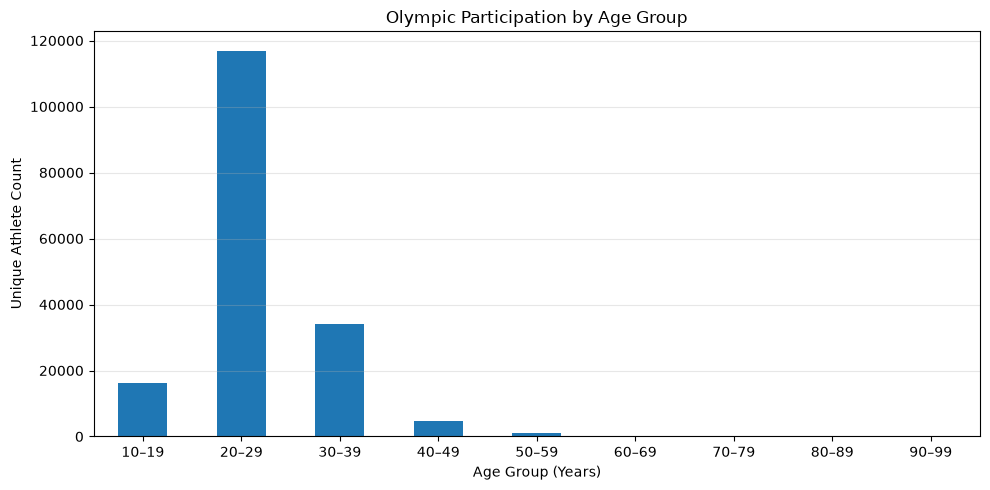

In [12]:

# Divide athlete ages into 10-year age groups
age_data['age_group'] = pd.cut(
    age_data['age'],
    bins=[10, 20, 30, 40, 50, 60, 70, 80, 90, 100],
    right=False,
    labels=[
        '10–19', '20–29', '30–39', '40–49',
        '50–59', '60–69', '70–79', '80–89', '90–99'
    ]
)

# Count unique athletes in each age group
age_group_counts = age_data.groupby(
    'age_group',
    observed=False
)['athlete_id'].nunique()

# Plot the age-group participation counts
age_group_counts.plot(kind='bar', figsize=(10, 5))

# Add chart labels and formatting
plt.title('Olympic Participation by Age Group')
plt.xlabel('Age Group (Years)')
plt.ylabel('Unique Athlete Count')
plt.xticks(rotation=0)
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()
plt.show()


Top 10 Sports by Unique Athlete Count:
sport
Athletics     25208
Swimming       9669
Football       8500
Rowing         8244
Boxing         5839
Wrestling      5148
Shooting       5058
Ice Hockey     4776
Sailing        4684
Hockey         4441
Name: athlete_id, dtype: int64


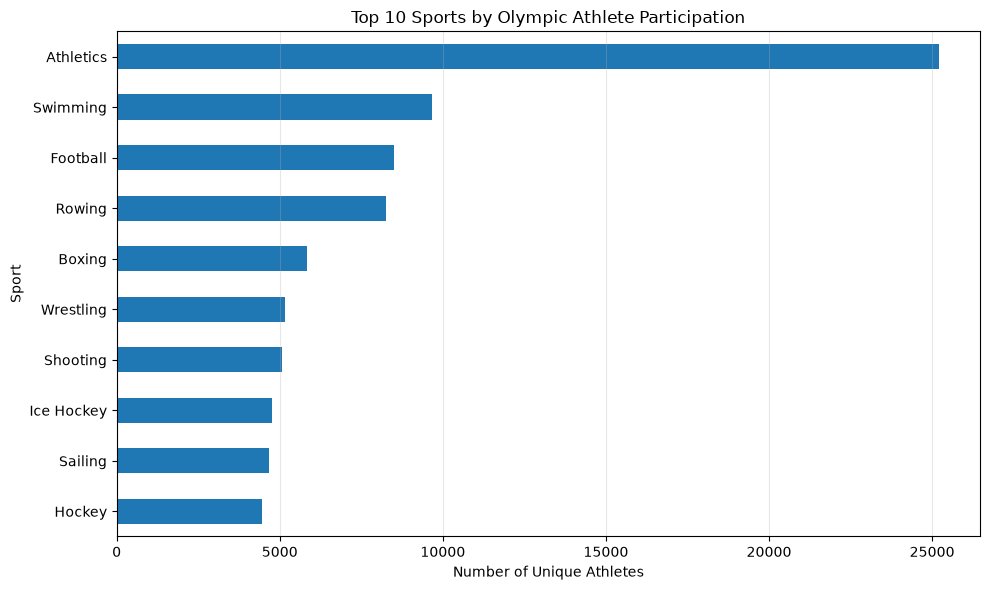

In [13]:

# Count unique athletes participating in each sport
sport_counts = (
    athlete_results.groupby('sport')['athlete_id']
    .nunique()
    .sort_values(ascending=False)
)

# Select the 10 sports with the highest athlete participation
top_10_sports = sport_counts.head(10)

# Display the top 10 sports and their athlete counts
print("Top 10 Sports by Unique Athlete Count:")
print(top_10_sports)

# Plot the top 10 sports
top_10_sports.sort_values().plot(
    kind='barh',
    figsize=(10, 6)
)

# Add chart labels and formatting
plt.title('Top 10 Sports by Olympic Athlete Participation')
plt.xlabel('Number of Unique Athletes')
plt.ylabel('Sport')
plt.grid(axis='x', alpha=0.3)
plt.tight_layout()
plt.show()


### EDA Question 2: Participation Trends Across Gender, Age and Sports

**1. Gender Participation:** The analysis shows a historical difference between male and female athlete participation. The year-wise line graph helps identify how female participation has increased over time and how the gap between male and female participation has changed.

**2. Age Distribution:** The average athlete age is approximately 26 years, while the median age is 25 years. The age-group chart helps identify the age ranges with the highest participation.

**3. Sport-wise Participation:** The top 10 sports analysis identifies the sports with the highest number of unique athlete IDs in the historical dataset.

**Conclusion:** Gender, age and sport are useful factors for understanding Olympic participation patterns. Visualising these factors helps identify historical changes and differences across athlete groups.


## EDA Question 3: Country-wise Performance Spikes and Dips


In [14]:

# Load the Olympic medal tally dataset
medals = pd.read_csv("Olympic_Games_Medal_Tally.csv")

# Display the actual columns before selecting or processing data
print("Columns:", medals.columns.tolist())

# Display a few records to understand the dataset structure
display(medals.head())

# Check which Olympic editions and countries are represented
print("\nNumber of rows:", len(medals))


Columns: ['edition', 'edition_id', 'year', 'country', 'country_noc', 'gold', 'silver', 'bronze', 'total']


,edition,edition_id,year,country,country_noc,gold,silver,bronze,total
0,1896 Summer Olympics,1,1896,United States,USA,11,7,2,20
1,1896 Summer Olympics,1,1896,Greece,GRE,10,18,19,47
2,1896 Summer Olympics,1,1896,Germany,GER,6,5,2,13
3,1896 Summer Olympics,1,1896,France,FRA,5,4,2,11
4,1896 Summer Olympics,1,1896,Great Britain,GBR,2,3,2,7



Number of rows: 1807


In [15]:

# Keep only Summer Olympics records for a consistent comparison
summer_medals = medals[
    medals['edition'].str.contains('Summer Olympics', na=False)
].copy()

# Sort countries chronologically by Olympic year
summer_medals = summer_medals.sort_values(
    ['country_noc', 'year']
)

# Calculate the previous edition's medal count for each country
summer_medals['previous_medals'] = (
    summer_medals.groupby('country_noc')['total'].shift(1)
)

# Calculate the change in medals compared with the previous recorded edition
summer_medals['medal_change'] = (
    summer_medals['total'] - summer_medals['previous_medals']
)

# Display records where a previous comparison is available
display(
    summer_medals[
        ['year', 'country', 'total', 'previous_medals', 'medal_change']
    ].head(15)
)


,year,country,total,previous_medals,medal_change
1072,2008,Afghanistan,1,NaN,NaN
1156,2012,Afghanistan,1,1.0,0.0
681,1988,Netherlands Antilles,1,NaN,NaN
636,1984,Algeria,2,NaN,NaN
727,1992,Algeria,2,2.0,0.0
791,1996,Algeria,3,2.0,1.0
878,2000,Algeria,5,3.0,2.0
1058,2008,Algeria,2,5.0,-3.0
1127,2012,Algeria,1,2.0,-1.0
1226,2016,Algeria,2,1.0,1.0


In [16]:

# Remove rows where no previous medal count is available
changes = summer_medals.dropna(subset=['medal_change']).copy()

# Find the 10 largest increases in medal counts
top_spikes = changes.sort_values(
    'medal_change', ascending=False
).head(10)

# Find the 10 largest decreases in medal counts
top_dips = changes.sort_values(
    'medal_change', ascending=True
).head(10)

# Display the biggest increases
print("Top 10 Medal Increases:")
display(
    top_spikes[
        ['year', 'country', 'previous_medals', 'total', 'medal_change']
    ]
)

# Display the biggest decreases
print("\nTop 10 Medal Decreases:")
display(
    top_dips[
        ['year', 'country', 'previous_medals', 'total', 'medal_change']
    ]
)


Top 10 Medal Increases:


,year,country,previous_medals,total,medal_change
30,1904,United States,48.0,248,200.0
38,1908,Great Britain,2.0,146,144.0
11,1900,France,11.0,112,101.0
595,1984,United States,94.0,174,80.0
191,1936,Germany,24.0,101,77.0
559,1980,Soviet Union,125.0,195,70.0
759,1996,Russian Federation,5.0,63,58.0
163,1932,United States,56.0,110,54.0
472,1972,East Germany,25.0,66,41.0
58,1912,Sweden,25.0,65,40.0



Top 10 Medal Decreases:


,year,country,previous_medals,total,medal_change
39,1908,United States,248.0,47,-201.0
59,1912,Great Britain,146.0,41,-105.0
41,1908,France,112.0,19,-93.0
644,1988,United States,174.0,94,-80.0
288,1952,Germany,101.0,24,-77.0
642,1988,Soviet Union,195.0,132,-63.0
192,1936,United States,110.0,57,-53.0
36,1904,Greece,47.0,2,-45.0
129,1928,United States,99.0,56,-43.0
105,1924,Sweden,64.0,29,-35.0


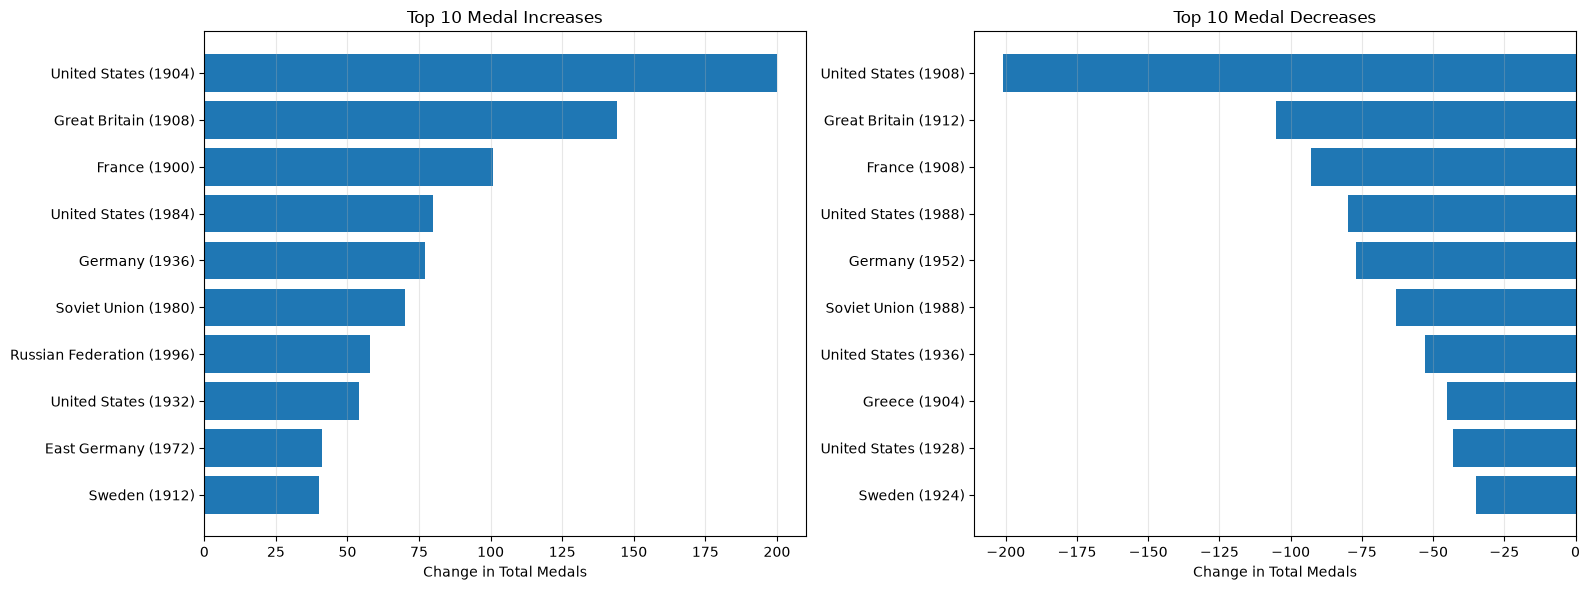

In [17]:

# Create two side-by-side charts for medal increases and decreases
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Plot the 10 largest medal increases
axes[0].barh(
    top_spikes['country'] + ' (' + top_spikes['year'].astype(str) + ')',
    top_spikes['medal_change']
)
axes[0].set_title('Top 10 Medal Increases')
axes[0].set_xlabel('Change in Total Medals')
axes[0].invert_yaxis()
axes[0].grid(axis='x', alpha=0.3)

# Plot the 10 largest medal decreases
axes[1].barh(
    top_dips['country'] + ' (' + top_dips['year'].astype(str) + ')',
    top_dips['medal_change']
)
axes[1].set_title('Top 10 Medal Decreases')
axes[1].set_xlabel('Change in Total Medals')
axes[1].invert_yaxis()
axes[1].grid(axis='x', alpha=0.3)

# Adjust spacing and display both charts
plt.tight_layout()
plt.show()


### EDA Question 3: Country-wise Performance Spikes and Dips

The analysis compares each country's total medal count with its previous recorded Summer Olympic edition.

- **Performance spikes:** Positive medal changes indicate an increase in the total number of medals.
- **Performance dips:** Negative medal changes indicate a decrease in the total number of medals.
- **Visual analysis:** The bar charts highlight the countries and Olympic editions with the largest medal-count changes.

**Conclusion:** Country-wise medal changes help identify major increases and decreases in Olympic medal counts over time. These changes should be interpreted in context because the number of events, participating countries, and competition structure can also affect medal totals.

## Dominance Trends of Countries in Specific Sports

In [18]:

# Check the medal values available in the athlete results dataset
print("Medal values:")
print(athlete_results['medal'].value_counts(dropna=False))

# Display the sports available in the dataset
print("\nTotal unique sports:", athlete_results['sport'].nunique())
print(athlete_results['sport'].dropna().unique()[:15])

# Check the country identifiers used in the dataset
print("\nSample country codes:")
print(athlete_results['country_noc'].dropna().unique()[:15])


Medal values:
medal
NaN       272147
Gold       15072
Bronze     14939
Silver     14676
Name: count, dtype: int64

Total unique sports: 112
<StringArray>
[          'Athletics',              'Boxing',              'Diving',
               'Rugby',            'Shooting',            'Swimming',
              'Rowing',              'Tennis', 'Artistic Gymnastics',
       'Cycling Track',             'Fencing',           'Wrestling',
    'Art Competitions',        'Cycling Road',   'Artistic Swimming']
Length: 15, dtype: str

Sample country codes:
<StringArray>
['ANZ', 'BOH', 'ARU', 'BAN', 'BHU', 'ASA', 'ANT', 'BRN', 'BEN', 'BIZ', 'BAR',
 'ALB', 'ANG', 'AFG', 'BRU']
Length: 15, dtype: str


In [19]:

# Keep only records where an athlete or team won a medal
medal_data = athlete_results[
    athlete_results['medal'].isin(['Gold', 'Silver', 'Bronze'])
].copy()

# Count medal-winning records for each sport and country
sport_country_medals = (
    medal_data.groupby(['sport', 'country_noc'])
    .size()
    .reset_index(name='medal_count')
)

# Rank countries within each sport by their historical medal counts
sport_country_medals['rank'] = (
    sport_country_medals.groupby('sport')['medal_count']
    .rank(method='dense', ascending=False)
)

# Display the top 5 countries in each sport
top_countries_by_sport = (
    sport_country_medals[sport_country_medals['rank'] <= 5]
    .sort_values(['sport', 'rank', 'country_noc'])
)

# Show a sample of the results
display(top_countries_by_sport.head(20))


,sport,country_noc,medal_count,rank
2,3x3 Basketball,ROC,8,1.0
0,3x3 Basketball,CHN,4,2.0
1,3x3 Basketball,LAT,4,2.0
3,3x3 Basketball,SRB,4,2.0
4,3x3 Basketball,USA,4,2.0
5,Aeronautics,SUI,1,1.0
7,Alpine Skiing,AUT,138,1.0
24,Alpine Skiing,SUI,79,2.0
13,Alpine Skiing,FRA,51,3.0
20,Alpine Skiing,NOR,50,4.0


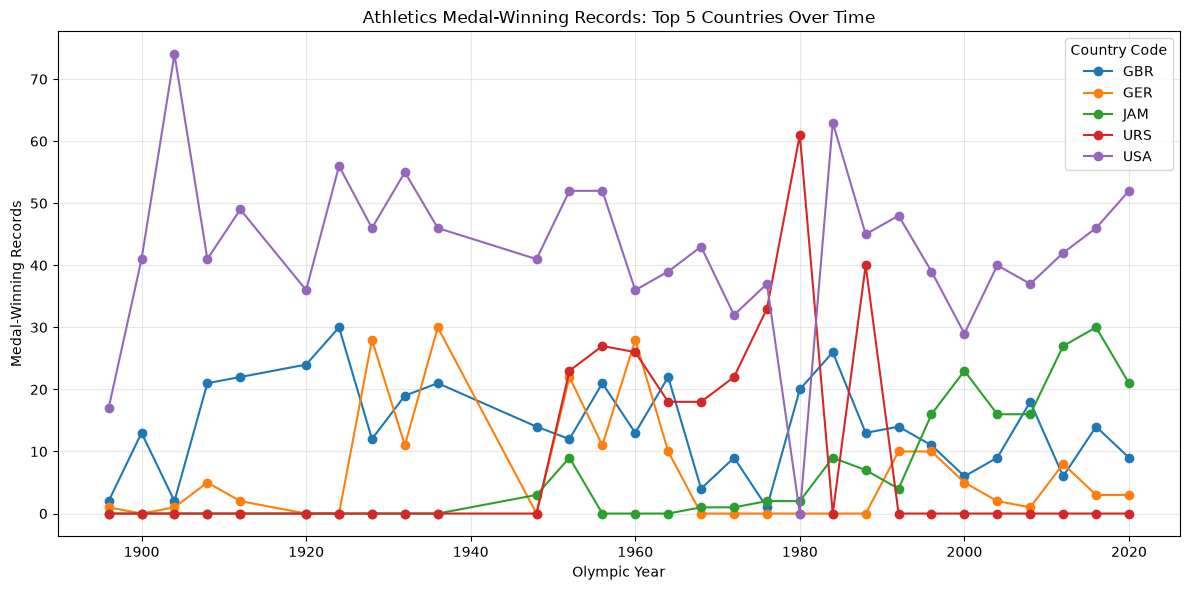

In [20]:

# Select medal-winning records from Athletics
athletics_data = medal_data[
    medal_data['sport'] == 'Athletics'
].copy()

# Extract the Olympic year from the edition name
athletics_data['year'] = (
    athletics_data['edition'].str[:4].astype(int)
)

# Count medal-winning records for each country in each Olympic year
athletics_trends = (
    athletics_data.groupby(['year', 'country_noc'])
    .size()
    .reset_index(name='medal_count')
)

# Find the five countries with the highest historical Athletics counts
top_athletics_countries = (
    athletics_trends.groupby('country_noc')['medal_count']
    .sum()
    .nlargest(5)
    .index
)

# Keep only those five countries for the trend chart
athletics_top5_trends = athletics_trends[
    athletics_trends['country_noc'].isin(top_athletics_countries)
]

# Reshape the data so each country becomes a separate chart line
athletics_pivot = athletics_top5_trends.pivot(
    index='year',
    columns='country_noc',
    values='medal_count'
).fillna(0)

# Plot the historical Athletics medal trends
athletics_pivot.plot(figsize=(12, 6), marker='o')

# Add chart labels and formatting
plt.title('Athletics Medal-Winning Records: Top 5 Countries Over Time')
plt.xlabel('Olympic Year')
plt.ylabel('Medal-Winning Records')
plt.legend(title='Country Code')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


### EDA Question 4: Dominance Trends of Countries in Specific Sports

The analysis compares countries' historical medal-winning records across different sports. The overall sport-wise ranking identifies countries with the highest medal-winning record counts, while the Athletics trend chart shows how these counts change across Olympic editions.

- **Sport-wise leaders:** Countries can have different levels of success in different sports.
- **Changes over time:** Year-wise trends help identify increases and decreases in medal-winning records.
- **Historical dominance:** Repeatedly high counts can indicate sustained success in a sport.

**Conclusion:** Sport-wise analysis helps reveal differences in countries' Olympic performance across disciplines. These findings should be interpreted as medal-winning record counts, not exact unique medal totals, because team events can include multiple athlete records.